# CoNLL-2003 Named Entity Recognition — Assignment 7


## 1. Install and import libraries

In [1]:
%pip -q install pandas numpy scikit-learn gensim seqeval kagglehub matplotlib torch

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, re, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report as token_report
from seqeval.metrics import f1_score, precision_score, recall_score, classification_report
from gensim.models import Word2Vec
from gensim import downloader as gensim_api

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE)

# For a quick practice run, change to True; final experiment: False.
FAST_MODE = False
EPOCHS = 2 if FAST_MODE else 5
BATCH_SIZE = 32
MAX_LENGTH = 80


Device: cpu


## 2. Download the data


In [3]:
import kagglehub
try:
    DATA_DIR = Path(kagglehub.dataset_download('alaakhaled/conll003-englishversion'))
    print('Downloaded to:', DATA_DIR)
except Exception as error:
    DATA_DIR = Path('data')
    print('Automatic download unavailable:', error)
    print('Put the extracted CoNLL files in:', DATA_DIR.resolve())

if DATA_DIR.exists():
    for file in DATA_DIR.rglob('*'):
        if file.is_file():
            print(file.relative_to(DATA_DIR))


100%|███████████████████████████████████████████████████████████████████████████████| 960k/960k [00:00<00:00, 1.49MB/s]

Extracting files...
Downloaded to: C:\Users\user\.cache\kagglehub\datasets\alaakhaled\conll003-englishversion\versions\1
metadata
test.txt
train.txt
valid.txt


### Find train, validation, and test files

In [4]:
def locate_split(folder, keywords):
    files = [p for p in folder.rglob('*') if p.is_file() and p.suffix.lower() in ('.txt', '.conll', '.bio', '.tsv', '')]
    matches = [p for p in files if any(k in p.stem.lower() for k in keywords)]
    if not matches:
        raise FileNotFoundError(f'No file matching {keywords} in {folder}. Check filenames above.')
    return sorted(matches, key=lambda p: len(p.name))[0]

train_path = locate_split(DATA_DIR, ['train'])
valid_path = locate_split(DATA_DIR, ['valid', 'dev'])
test_path = locate_split(DATA_DIR, ['test'])
print('Training:', train_path.name, '\nValidation:', valid_path.name, '\nTest:', test_path.name)


Training: train.txt 
Validation: valid.txt 
Test: test.txt


### Read the CoNLL format

Each token has four columns: **word, POS tag, chunk tag, NER tag**. Sentences are separated by empty lines. The label is always the *last* column.

In [5]:
def read_conll(path):
    sentences, words, tags, pos_tags, chunks = [], [], [], [], []
    def finish_sentence():
        if words:
            sentences.append({'words': words.copy(), 'tags': tags.copy(),
                              'pos': pos_tags.copy(), 'chunk': chunks.copy()})
            words.clear(); tags.clear(); pos_tags.clear(); chunks.clear()

    with open(path, encoding='utf-8') as f:
        for raw_line in f:
            line = raw_line.strip()
            if not line:
                finish_sentence()
                continue
            parts = line.split()
            if parts[0].startswith('-DOCSTART-'):
                finish_sentence()
                continue
            if len(parts) < 4:
                raise ValueError(f'Unexpected row in {path.name}: {line}')
            words.append(parts[0]); pos_tags.append(parts[1]); chunks.append(parts[2]); tags.append(parts[-1])
    finish_sentence()
    return sentences

train_data = read_conll(train_path)
valid_data = read_conll(valid_path)
test_data = read_conll(test_path)
if FAST_MODE:
    train_data, valid_data, test_data = train_data[:2000], valid_data[:400], test_data[:400]
print('Sentences:', len(train_data), len(valid_data), len(test_data))
print(pd.DataFrame(train_data[0]))


Sentences: 14041 3250 3453
     words    tags  pos chunk
0       EU   B-ORG  NNP  B-NP
1  rejects       O  VBZ  B-VP
2   German  B-MISC   JJ  B-NP
3     call       O   NN  I-NP
4       to       O   TO  B-VP
5  boycott       O   VB  I-VP
6  British  B-MISC   JJ  B-NP
7     lamb       O   NN  I-NP
8        .       O    .     O


## 3. Evaluation

The assignment requires **entity-level F1**. All words in a predicted entity must have the correct BIO tags (including the boundaries and entity type). We also calculate precision, recall, and class-wise results.

In [6]:
all_results = []

def evaluate_model(name, predictions, true_sentences):
    actual = [s['tags'] for s in true_sentences]
    assert len(predictions) == len(actual)
    assert all(len(p) == len(t) for p, t in zip(predictions, actual))
    row = {'Model': name,
           'Precision': precision_score(actual, predictions),
           'Recall': recall_score(actual, predictions),
           'F1': f1_score(actual, predictions)}
    all_results.append(row)
    print(name)
    print(classification_report(actual, predictions, digits=3, zero_division=0))
    return row

def show_results():
    return pd.DataFrame(all_results).sort_values('F1', ascending=False).reset_index(drop=True)


## 4. Experiment 1 — N-gram features + Logistic Regression

A basic baseline: predict each word using its own shape, previous/next words, and local n-gram context. We use Logistic Regression because it is simple and fast.

In [7]:
def word_features(words, index):
    word = words[index]
    previous = words[index - 1] if index > 0 else '<START>'
    following = words[index + 1] if index + 1 < len(words) else '<END>'
    return {
        'word': word.lower(), 'previous': previous.lower(), 'next': following.lower(),
        'previous+word': previous.lower() + '|' + word.lower(),
        'word+next': word.lower() + '|' + following.lower(),
        'prefix': word[:3].lower(), 'suffix': word[-3:].lower(),
        'is_title': word.istitle(), 'is_upper': word.isupper(), 'is_digit': word.isdigit(),
    }

def make_ngram_rows(sentences):
    x = [word_features(s['words'], i) for s in sentences for i in range(len(s['words']))]
    y = [tag for s in sentences for tag in s['tags']]
    return x, y

vectorizer = DictVectorizer(sparse=True)
train_features, train_labels = make_ngram_rows(train_data)
valid_features, _ = make_ngram_rows(valid_data)
X_train = vectorizer.fit_transform(train_features)
X_valid = vectorizer.transform(valid_features)
ngram_model = LogisticRegression(max_iter=200, solver='lbfgs')
ngram_model.fit(X_train, train_labels)

def regroup(flat_tags, sentences):
    predictions = []
    offset = 0
    for sentence in sentences:
        count = len(sentence['words'])
        predictions.append(list(flat_tags[offset:offset+count]))
        offset += count
    return predictions

ngram_pred = regroup(ngram_model.predict(X_valid), valid_data)
evaluate_model('N-gram + Logistic Regression', ngram_pred, valid_data)


N-gram + Logistic Regression
              precision    recall  f1-score   support

         LOC      0.884     0.866     0.875      1837
        MISC      0.859     0.787     0.822       922
         ORG      0.683     0.716     0.699      1341
         PER      0.785     0.868     0.824      1842

   micro avg      0.801     0.820     0.811      5942
   macro avg      0.803     0.809     0.805      5942
weighted avg      0.804     0.820     0.811      5942



{'Model': 'N-gram + Logistic Regression',
 'Precision': np.float64(0.8011503697617092),
 'Recall': np.float64(0.8204308313699091),
 'F1': np.float64(0.8106759790471438)}

## 5. Train Word2Vec and load GloVe

Word2Vec learns vectors from the training words (no test data). GloVe uses publicly available pretrained word vectors, downloaded by Gensim. The first download can be slow.

In [8]:
word2vec = Word2Vec(
    sentences=[[w.lower() for w in s['words']] for s in train_data],
    vector_size=50, window=5, min_count=1, workers=2, epochs=10, seed=SEED
)
print('Word2Vec vocabulary:', len(word2vec.wv))

# Downloads ~66 MB once (requires internet on first run).
glove = gensim_api.load('glove-wiki-gigaword-50')
print('GloVe loaded')


Word2Vec vocabulary: 21009
[==================================================] 100.0% 66.0/66.0MB downloaded
GloVe loaded


## 6. Experiments 2 and 3 — Word2Vec/GloVe + Logistic Regression

We use a simple **Logistic Regression** classifier for both embeddings so the comparison is fair. Each input uses the previous, current, and next word vectors concatenated together.

In [18]:
embedding_classifiers = {}

In [ ]:
def lookup_vector(word, embedding, size=50):
    word = word.lower()
    if embedding == 'word2vec':
        return word2vec.wv[word] if word in word2vec.wv else np.zeros(size)
    return glove[word] if word in glove else np.zeros(size)

def embedding_rows(sentences, embedding):
    rows = []
    for sentence in sentences:
        words = sentence['words']
        for i in range(len(words)):
            context = [words[j] if 0 <= j < len(words) else '' for j in (i-1, i, i+1)]
            rows.append(np.concatenate([lookup_vector(w, embedding) for w in context]))
    return np.asarray(rows, dtype=np.float32)

for embedding_name in ['word2vec', 'glove']:
    x_train_emb = embedding_rows(train_data, embedding_name)
    x_valid_emb = embedding_rows(valid_data, embedding_name)
    classifier = LogisticRegression(max_iter=300)
    classifier.fit(x_train_emb, train_labels)
    embedding_classifiers[embedding_name] = classifier
    predicted = regroup(classifier.predict(x_valid_emb), valid_data)
    evaluate_model(f'{embedding_name.upper()} + Logistic Regression', predicted, valid_data)


C:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


WORD2VEC + Logistic Regression
              precision    recall  f1-score   support

         LOC      0.698     0.484     0.572      1837
        MISC      0.332     0.069     0.115       922
         ORG      0.503     0.230     0.315      1341
         PER      0.392     0.410     0.401      1842

   micro avg      0.503     0.339     0.405      5942
   macro avg      0.481     0.298     0.351      5942
weighted avg      0.502     0.339     0.390      5942



## 7. Build the LSTM training pipeline

For the next two experiments, the target is a BIO tag for **every token**. Sentences are padded in batches, and padding positions are excluded from the loss. For fair evaluation, the LSTMs also use the same training and validation split.

In [10]:
from collections import Counter
vocab_count = Counter(w.lower() for s in train_data for w in s['words'])
word_to_id = {'<PAD>': 0, '<UNK>': 1}
for word in vocab_count:
    word_to_id[word] = len(word_to_id)

tag_names = sorted({t for s in train_data for t in s['tags']})
tag_to_id = {tag: i for i, tag in enumerate(tag_names)}
id_to_tag = {i: tag for tag, i in tag_to_id.items()}
print('Vocabulary:', len(word_to_id), 'Tags:', tag_names)

class NERDataset(Dataset):
    def __init__(self, sentences): self.sentences = sentences
    def __len__(self): return len(self.sentences)
    def __getitem__(self, i):
        s = self.sentences[i]
        return ([word_to_id.get(w.lower(), 1) for w in s['words']],
                [tag_to_id[t] for t in s['tags']])

def collate(batch):
    lengths = [len(x) for x, _ in batch]
    max_len = max(lengths)
    words = torch.zeros((len(batch), max_len), dtype=torch.long)
    labels = torch.full((len(batch), max_len), -100, dtype=torch.long)
    for i, (x, y) in enumerate(batch):
        words[i, :len(x)] = torch.tensor(x)
        labels[i, :len(y)] = torch.tensor(y)
    return words, labels, lengths

train_loader = DataLoader(NERDataset(train_data), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
valid_loader = DataLoader(NERDataset(valid_data), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate)


Vocabulary: 21011 Tags: ['B-LOC', 'B-MISC', 'B-ORG', 'B-PER', 'I-LOC', 'I-MISC', 'I-ORG', 'I-PER', 'O']


### Define one LSTM model used in two ways

- **Experiment 4:** Input vectors built from the Word2Vec and GloVe embeddings, plus an n-gram context mean (previous/current/next Word2Vec vectors). The vectors are fixed; the LSTM is trained.
- **Experiment 5:** A trainable embedding layer, learned together with the LSTM.

This makes the input method the main difference between the two LSTM experiments.

In [11]:
def make_pretrained_matrix(embedding_type):
    matrix = np.zeros((len(word_to_id), 50), dtype=np.float32)
    for word, idx in word_to_id.items():
        if idx > 1:
            matrix[idx] = lookup_vector(word, embedding_type)
    return torch.tensor(matrix)

w2v_matrix = make_pretrained_matrix('word2vec')
glove_matrix = make_pretrained_matrix('glove')

class LSTMTagger(nn.Module):
    def __init__(self, use_pretrained):
        super().__init__()
        self.use_pretrained = use_pretrained
        if use_pretrained:
            self.w2v = nn.Embedding.from_pretrained(w2v_matrix, freeze=True, padding_idx=0)
            self.glove = nn.Embedding.from_pretrained(glove_matrix, freeze=True, padding_idx=0)
            input_size = 150
        else:
            self.embedding = nn.Embedding(len(word_to_id), 100, padding_idx=0)
            input_size = 100
        self.lstm = nn.LSTM(input_size, 64, batch_first=True, bidirectional=True)
        self.output = nn.Linear(128, len(tag_names))

    def forward(self, words):
        if self.use_pretrained:
            w2v = self.w2v(words)
            glove_vec = self.glove(words)
            # Context feature based on neighboring words (3-gram window)
            left = torch.cat([torch.zeros_like(w2v[:, :1]), w2v[:, :-1]], dim=1)
            right = torch.cat([w2v[:, 1:], torch.zeros_like(w2v[:, :1])], dim=1)
            context = (left + w2v + right) / 3
            x = torch.cat([w2v, glove_vec, context], dim=-1)
        else:
            x = self.embedding(words)
        features, _ = self.lstm(x)
        return self.output(features)

def train_lstm(model):
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.002)
    loss_fn = nn.CrossEntropyLoss(ignore_index=-100)
    for epoch in range(EPOCHS):
        model.train(); total_loss = 0
        for words, labels, _ in train_loader:
            words, labels = words.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            output = model(words)
            loss = loss_fn(output.reshape(-1, len(tag_names)), labels.reshape(-1))
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f'Epoch {epoch+1}/{EPOCHS} - loss: {total_loss / len(train_loader):.4f}')
    return model

@torch.no_grad()
def predict_lstm(model, loader):
    model.eval(); result = []
    for words, _, lengths in loader:
        tag_ids = model(words.to(DEVICE)).argmax(dim=-1).cpu().tolist()
        for ids, length in zip(tag_ids, lengths):
            result.append([id_to_tag[i] for i in ids[:length]])
    return result


## 8. Experiment 4 — LSTM with N-gram + Word2Vec + GloVe features

In [12]:
feature_lstm = train_lstm(LSTMTagger(use_pretrained=True))
feature_predictions = predict_lstm(feature_lstm, valid_loader)
evaluate_model('LSTM + N-gram/W2V/GloVe features', feature_predictions, valid_data)


Epoch 1/5 - loss: 0.3195
Epoch 2/5 - loss: 0.1470
Epoch 3/5 - loss: 0.1131
Epoch 4/5 - loss: 0.0929
Epoch 5/5 - loss: 0.0793
LSTM + N-gram/W2V/GloVe features
              precision    recall  f1-score   support

         LOC      0.912     0.869     0.890      1837
        MISC      0.829     0.709     0.764       922
         ORG      0.764     0.687     0.723      1341
         PER      0.886     0.806     0.844      1842

   micro avg      0.859     0.784     0.820      5942
   macro avg      0.848     0.768     0.806      5942
weighted avg      0.858     0.784     0.819      5942



{'Model': 'LSTM + N-gram/W2V/GloVe features',
 'Precision': np.float64(0.8590405904059041),
 'Recall': np.float64(0.7835745540222148),
 'F1': np.float64(0.8195740186586868)}

## 9. Experiment 5 — LSTM with a learned embedding layer

In [13]:
embedding_lstm = train_lstm(LSTMTagger(use_pretrained=False))
embedding_predictions = predict_lstm(embedding_lstm, valid_loader)
evaluate_model('LSTM + trainable Embedding', embedding_predictions, valid_data)


Epoch 1/5 - loss: 0.5125
Epoch 2/5 - loss: 0.1951
Epoch 3/5 - loss: 0.0991
Epoch 4/5 - loss: 0.0508
Epoch 5/5 - loss: 0.0254
LSTM + trainable Embedding
              precision    recall  f1-score   support

         LOC      0.851     0.833     0.842      1837
        MISC      0.600     0.742     0.663       922
         ORG      0.680     0.660     0.670      1341
         PER      0.747     0.695     0.720      1842

   micro avg      0.736     0.737     0.736      5942
   macro avg      0.719     0.732     0.724      5942
weighted avg      0.741     0.737     0.738      5942



{'Model': 'LSTM + trainable Embedding',
 'Precision': np.float64(0.7355954980682009),
 'Recall': np.float64(0.7369572534500168),
 'F1': np.float64(0.7362757461118116)}

## 10. Compare all five experiments

,Model,Precision,Recall,F1
0,LSTM + N-gram/W2V/GloVe features,0.8590,0.7836,0.8196
1,N-gram + Logistic Regression,0.8012,0.8204,0.8107
2,LSTM + trainable Embedding,0.7356,0.7370,0.7363
3,GLOVE + Logistic Regression,0.6688,0.5909,0.6274
4,WORD2VEC + Logistic Regression,0.5030,0.3394,0.4053


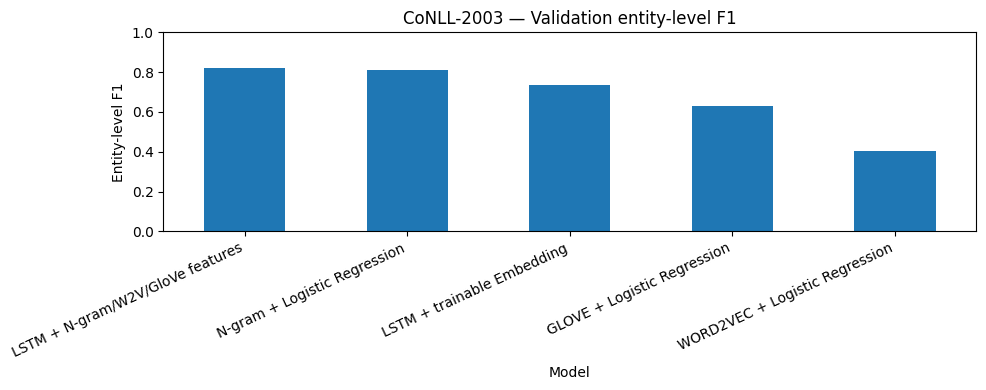

In [14]:
results_df = show_results()
display(results_df.round(4))
ax = results_df.plot.bar(x='Model', y='F1', legend=False, figsize=(10, 4))
ax.set_title('CoNLL-2003 — Validation entity-level F1')
ax.set_ylabel('Entity-level F1')
ax.set_ylim(0, 1)
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()
results_df.to_csv('ner_validation_results.csv', index=False)


## 11. Final test evaluation (only after choosing the model)

We choose the model from validation performance, then report its **test** score. For simplicity, this section reuses the already-trained matching model. It does not use the test set to select a model.

In [15]:
best_name = results_df.iloc[0]['Model']
print('Validation winner:', best_name)
if best_name == 'N-gram + Logistic Regression':
    test_x, _ = make_ngram_rows(test_data)
    test_predictions = regroup(ngram_model.predict(vectorizer.transform(test_x)), test_data)
elif best_name == 'WORD2VEC + Logistic Regression' or best_name == 'GLOVE + Logistic Regression':
    # Refit the same classifier to the original training split.
    emb = 'word2vec' if best_name.startswith('WORD2VEC') else 'glove'
    final_clf = LogisticRegression(max_iter=300)
    final_clf.fit(embedding_rows(train_data, emb), train_labels)
    test_predictions = regroup(final_clf.predict(embedding_rows(test_data, emb)), test_data)
elif best_name == 'LSTM + N-gram/W2V/GloVe features':
    test_predictions = predict_lstm(feature_lstm, DataLoader(NERDataset(test_data), batch_size=BATCH_SIZE, collate_fn=collate))
else:
    test_predictions = predict_lstm(embedding_lstm, DataLoader(NERDataset(test_data), batch_size=BATCH_SIZE, collate_fn=collate))

print('FINAL TEST RESULT (best validation model):')
print(classification_report([s['tags'] for s in test_data], test_predictions, digits=3, zero_division=0))


Validation winner: LSTM + N-gram/W2V/GloVe features
FINAL TEST RESULT (best validation model):
              precision    recall  f1-score   support

         LOC      0.852     0.795     0.822      1668
        MISC      0.695     0.632     0.662       702
         ORG      0.714     0.627     0.668      1661
         PER      0.846     0.701     0.767      1617

   micro avg      0.790     0.699     0.741      5648
   macro avg      0.777     0.689     0.730      5648
weighted avg      0.790     0.699     0.741      5648



## 12. Example prediction and checks

In [16]:
example_id = 0
print('Sentence:', ' '.join(test_data[example_id]['words']))
print(pd.DataFrame({'Word': test_data[example_id]['words'],
                    'True': test_data[example_id]['tags'],
                    'Predicted': test_predictions[example_id]}).head(30))


Sentence: SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRISE DEFEAT .
        Word   True Predicted
0     SOCCER      O         O
1          -      O         O
2      JAPAN  B-LOC     B-LOC
3        GET      O         O
4      LUCKY      O         O
5        WIN      O         O
6          ,      O         O
7      CHINA  B-PER     B-LOC
8         IN      O         O
9   SURPRISE      O         O
10    DEFEAT      O         O
11         .      O         O


In [20]:
import joblib
from pathlib import Path
import torch

# Save models in the project folder
project_dir = Path.cwd()

if project_dir.name.lower() == "notebook":
    project_dir = project_dir.parent

models_dir = project_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# 1. Save N-gram model and vectorizer
joblib.dump(ngram_model, models_dir / "ngram_model.joblib")
joblib.dump(vectorizer, models_dir / "ngram_vectorizer.joblib")

# 2. Save Word2Vec classifier
joblib.dump(
    embedding_classifiers["word2vec"],
    models_dir / "word2vec_classifier.joblib"
)

# 3. Save GloVe classifier
joblib.dump(
    embedding_classifiers["glove"],
    models_dir / "glove_classifier.joblib"
)

# 4. Save Word2Vec embeddings
word2vec.save(str(models_dir / "word2vec.model"))

# 5. Save GloVe embeddings
glove.save(str(models_dir / "glove_vectors.kv"))

# 6. Save LSTM with pretrained features
torch.save(
    feature_lstm.cpu().state_dict(),
    models_dir / "feature_lstm.pth"
)

# 7. Save LSTM with embedding layer
torch.save(
    embedding_lstm.cpu().state_dict(),
    models_dir / "embedding_lstm.pth"
)

# 8. Save vocabulary and label mappings
metadata = {
    "word_to_id": word_to_id,
    "tag_to_id": tag_to_id,
    "id_to_tag": id_to_tag,
    "tag_names": tag_names
}

joblib.dump(metadata, models_dir / "metadata.joblib")

print("All 5 models saved successfully!")
print("Saved to:", models_dir)

All 5 models saved successfully!
Saved to: C:\Users\user\Downloads\conll2003-ner-comparison\models
